In [1]:
import nibabel as nib
import numpy as np

vol_path = "data/volume_pt1/volume-0.nii" # Input CT 영상
seg_path = "data/segmentations/segmentation-0.nii" # GT Sementation 결과

vol_img = nib.load(vol_path)
seg_img = nib.load(seg_path)

print("== CT volume ==")
print("shape   :", vol_img.shape)
print("spacing :", vol_img.header.get_zooms())        # (x, y, z) mm
print("dtype   :", vol_img.get_data_dtype())
print("orient  :", nib.aff2axcodes(vol_img.affine))

print("\n== Segmentation ==")
print("shape   :", seg_img.shape)
print("spacing :", seg_img.header.get_zooms())
print("dtype   :", seg_img.get_data_dtype())

vol = vol_img.get_fdata()
seg = np.asanyarray(seg_img.dataobj)

print("\n== Values ==")
print("CT HU range :", vol.min(), "~", vol.max())
print("Seg labels  :", np.unique(seg, return_counts=True))


== CT volume ==
shape   : (512, 512, 75)
spacing : (0.703125, 0.703125, 5.0)
dtype   : int16
orient  : ('L', 'A', 'S')

== Segmentation ==
shape   : (512, 512, 75)
spacing : (0.703125, 0.703125, 5.0)
dtype   : int16

== Values ==
CT HU range : -3024.0 ~ 1410.0
Seg labels  : (array([0, 1, 2], dtype=int16), array([19108173,   550036,     2591], dtype=int64))


In [3]:
labels, counts = np.unique(seg, return_counts=True)

for label, count in zip(labels, counts):
    ratio = count / seg.size * 100
    print(f"Label {label}: {count:,} voxels ({ratio:.4f}%)")

Label 0: 19,108,173 voxels (97.1892%)
Label 1: 550,036 voxels (2.7976%)
Label 2: 2,591 voxels (0.0132%)


### Class 불균형이 매우 심한 상태임. 

1. 전체 Accuracy 보다는 Recall이나 관심 Class 위주로 봐야 함
2. Tumor가 포함된 Slice를 학습해서 더 자주 선택하거나 하는 Sampling 전략

slice: 58


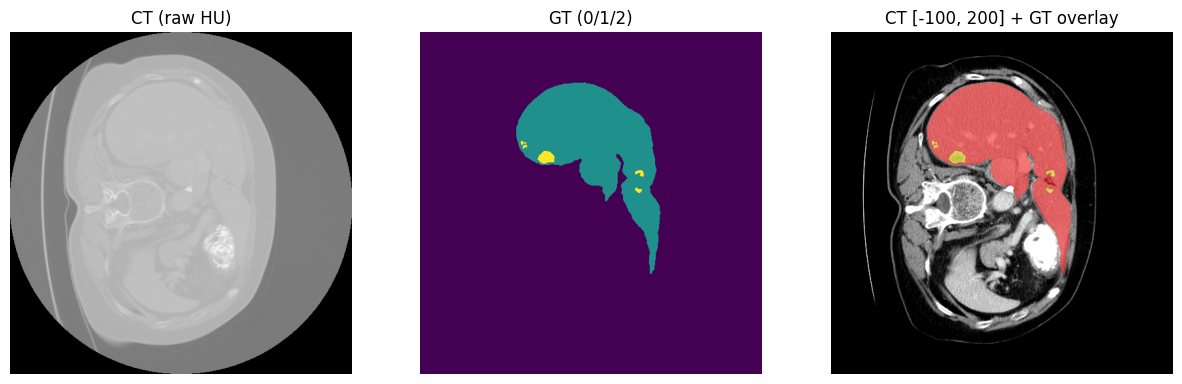

In [4]:
import matplotlib.pyplot as plt

# 종양 면적이 가장 큰 slice 고르기
k = int(np.argmax((seg == 2).sum(axis=(0, 1))))
print("slice:", k)

ct  = vol[:, :, k]
msk = seg[:, :, k]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(ct, cmap="gray");                         ax[0].set_title("CT (raw HU)")
ax[1].imshow(msk, cmap="viridis", vmin=0, vmax=2);     ax[1].set_title("GT (0/1/2)")
ax[2].imshow(ct, cmap="gray", vmin=-100, vmax=200)     # 간 위주로 보기 좋은 HU 범위
ax[2].imshow(np.ma.masked_where(msk == 0, msk), cmap="autumn", alpha=0.5, vmin=1, vmax=2)
ax[2].set_title("CT [-100, 200] + GT overlay")
for a in ax: a.axis("off")
plt.show()


In [8]:
def build_slice_index(data_dir, volume_ids, liver_only=True):
    """(volume_id, slice_idx) 리스트 반환"""
    index = []
    for vid in volume_ids:
        seg = np.asanyarray(nib.load(f"{data_dir}/segmentations/segmentation-{vid}.nii").dataobj)
        for k in range(seg.shape[2]):
            if liver_only and not seg[:,:,k].any():   # TODO: k번째 slice에 라벨이 하나도 없으면 건너뛰기
                continue
            index.append((vid, k))
    return index

idx = build_slice_index("data", volume_ids=range(11))
print(len(idx), idx[:5]) # 간, 종양이 있는 slice가 총 몇개고, 몇번 환자의 몇번 Slice인지


1688 [(0, 45), (0, 46), (0, 47), (0, 48), (0, 49)]


In [9]:
def hu_window(ct, w_min=-100, w_max=200):
    """CT slice (HU) → 0~1 float32"""
    ct = np.clip(ct, w_min, w_max)
    ct = (ct-w_min) / (w_max - w_min)
    ct = ct.astype('float32')
    return ct


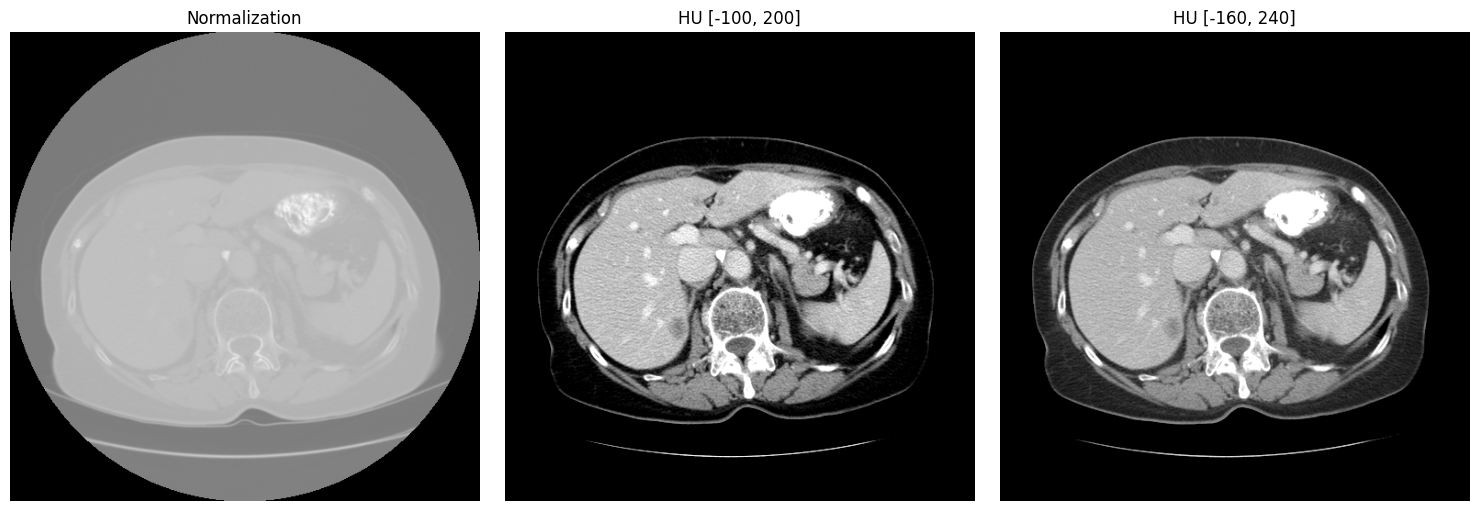

In [22]:
# 종양이 존재하는 Slice 선택
slice_idx = 58  # 종양이 존재하는 Slice 번호
ct = vol[:, :, slice_idx]

# 세 가지 전처리 적용

# Min-Max Normalization
ct_minmax = (ct - ct.min()) / (ct.max() - ct.min())

# HU Windowing [-100, 200]
ct_window1 = hu_window(ct, -100, 200)

# HU Windowing [-160, 240]
ct_window2 = hu_window(ct, -160, 240)


# 시각화
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [ct_minmax, ct_window1, ct_window2]
titles = [
    "Normalization",
    "HU [-100, 200]",
    "HU [-160, 240]"
]

for i in range(3):
    axes[i].imshow(
        np.rot90(images[i]),   # i번째 전처리 영상
        cmap="gray",
        vmin=0,
        vmax=1 
    )

    axes[i].set_title(titles[i])
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn as nn

m = seg[:, :, slice_idx]            # numpy, int16, (512, 512)

mask_t = torch.from_numpy(m).long() # int64로 바꾸기 위해서 long() 붙여야 함
print(mask_t.shape, mask_t.dtype, mask_t.unique())

# CrossEntropyLoss에 맞는 형식인지 테스트 (가짜 모델 출력)
logits = torch.randn(1, 3, 512, 512)          # (B, C, H, W)
loss = nn.CrossEntropyLoss()(logits, mask_t.unsqueeze(0))   # 마스크에 batch 차원 추가 → (1, 512, 512)
print("loss:", loss.item())


torch.Size([512, 512]) torch.int64 tensor([0, 1, 2])
loss: 1.3875627517700195


### Class 생성 Test

In [2]:
import importlib, dataset
importlib.reload(dataset)          # dataset.py를 수정한 뒤에는 다시 불러와야 반영됨
from dataset import LiTSDataset

ds = LiTSDataset("data", volume_ids=[0], img_size=256)
print("len:", len(ds))             # volume-0이면 29가 나와야 함 (Task 3 표)

image, mask = ds[0]
print("image:", image.shape, image.dtype, image.min().item(), image.max().item())
print("mask :", mask.shape, mask.dtype, mask.unique())


len: 29
image: torch.Size([1, 256, 256]) torch.float32 0.0 1.0
mask : torch.Size([256, 256]) torch.int64 tensor([0, 1])


In [3]:
from torch.utils.data import DataLoader

train_ds = LiTSDataset("data", volume_ids=range(0, 8)) # 환자별로 분할
val_ds   = LiTSDataset("data", volume_ids=[8, 9])
test_ds  = LiTSDataset("data", volume_ids=[10])
print("train / val / test:", len(train_ds), len(val_ds), len(test_ds))

train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)

images, masks = next(iter(train_loader))   # batch 1개만 꺼내기
print("images:", images.shape, images.dtype)
print("masks :", masks.shape, masks.dtype, masks.unique())


train / val / test: 1155 352 181
images: torch.Size([4, 1, 256, 256]) torch.float32
masks : torch.Size([4, 256, 256]) torch.int64 tensor([0, 1])


분할은 Volume 단위(Patient)로 나누다보니 Slice  건수를 보면 다를 수도 있어서 분할 할 때, Slice 건수 체크를 우서적으로 하자

In [4]:
importlib.reload(dataset)
from dataset import get_loaders

train_loader, val_loader, test_loader = get_loaders("data", batch_size=4, num_workers=0)

for name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    vids = sorted({vid for vid, _ in loader.dataset.index})
    print(f"{name:5s} slices={len(loader.dataset):5d}  volumes={vids}")


train slices= 1155  volumes=[0, 1, 2, 3, 4, 5, 6, 7]
val   slices=  352  volumes=[8, 9]
test  slices=  181  volumes=[10]


### train 체크

In [5]:
import importlib, torch, torch.nn as nn
import dataset, model, utils
for m in (dataset, model, utils): importlib.reload(m)

device = "cuda"
train_loader, val_loader, _ = dataset.get_loaders("data", batch_size=4, num_workers=0)
images, masks = next(iter(train_loader))
images, masks = images.to(device), masks.to(device)

net = model.UNet(in_channels=1, out_channels=3).to(device)
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(net.parameters(), lr=1e-3)

# ① Forward: shape 확인
logits = net(images)
print("images", images.shape, "masks", masks.shape, "logits", logits.shape)

# ② 같은 batch 하나로 30번 학습 → loss가 내려가는지 (과적합 테스트)
torch.cuda.reset_peak_memory_stats()
for step in range(30):
    logits = net(images)
    loss = loss_fn(logits, masks)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 5 == 0 or step == 29:
        s = utils.dice_stats_per_class(logits, masks)
        liver = 2 * s[1][0] / (s[1][1] + s[1][2] + 1e-8)
        tumor = 2 * s[2][0] / (s[2][1] + s[2][2] + 1e-8)
        print(f"step {step:2d}  loss {loss.item():.4f}  liver {liver:.3f}  tumor {tumor:.3f}")

print(f"GPU peak: {torch.cuda.max_memory_allocated() / 2**30:.2f} GB")


images torch.Size([4, 1, 256, 256]) masks torch.Size([4, 256, 256]) logits torch.Size([4, 3, 256, 256])
step  0  loss 1.3868  liver 0.052  tumor 0.034
step  5  loss 0.8681  liver 0.251  tumor 0.000
step 10  loss 0.6434  liver 0.657  tumor 0.000
step 15  loss 0.5074  liver 0.828  tumor 0.000
step 20  loss 0.4319  liver 0.846  tumor 0.000
step 25  loss 0.3666  liver 0.867  tumor 0.000
step 29  loss 0.3212  liver 0.874  tumor 0.000
GPU peak: 2.74 GB


In [6]:
import importlib, torch, utils
importlib.reload(utils)
dice_loss = utils.DiceLoss()

targets = torch.randint(0, 3, (2, 64, 64))                    # 가짜 정답 (0/1/2)

# ① 완벽한 예측: 정답 클래스에 아주 큰 점수
perfect = torch.nn.functional.one_hot(targets, 3).permute(0, 3, 1, 2).float() * 20
# ② 무작위 예측
random_ = torch.randn(2, 3, 64, 64)
# ③ 완전히 틀린 예측: 정답이 아닌 클래스에 큰 점수
wrong = perfect.roll(1, dims=1)

for name, logits in [("perfect", perfect), ("random", random_), ("wrong", wrong)]:
    print(f"{name:8s} loss = {dice_loss(logits, targets).item():.4f}")

# ④ gradient가 흐르는지 (Dice "지표"와의 핵심 차이)
logits = torch.randn(2, 3, 64, 64, requires_grad=True)
dice_loss(logits, targets).backward()
print("grad 있음:", logits.grad is not None, "| grad 크기:", logits.grad.abs().mean().item())


perfect  loss = 0.0000
random   loss = 0.6660
wrong    loss = 0.9998
grad 있음: True | grad 크기: 1.4161199032969307e-05


In [8]:
importlib.reload(utils)
logits = torch.randn(2, 3, 64, 64)
ce, dl, both = torch.nn.CrossEntropyLoss(), utils.DiceLoss(), utils.CEDiceLoss()
print(ce(logits, targets).item() + dl(logits, targets).item(), both(logits, targets).item())   # 두 값이 같아야 함


2.0693827867507935 2.069382667541504


### 실제 CT Segmentation 해보기

In [1]:
import importlib, torch, numpy as np, matplotlib.pyplot as plt
import dataset, model, utils
for m in (dataset, model, utils): importlib.reload(m)

device = "cuda"

# ① 모델 3개 불러오기
models = {}
for name in ["ce", "dice", "ce_dice"]:
    net = model.UNet(in_channels=1, out_channels=3).to(device)
    utils.load_checkpoint(f"checkpoints/{name}/best_model.pth", net, map_location=device)
    net.eval()                  # TODO 확인: 왜 꼭 eval()로 바꿔야 할까요?
    models[name] = net

# ② test set (volume 10)
test_ds = dataset.LiTSDataset("data", volume_ids=[10])
print("test slices:", len(test_ds))

# ③ slice마다 종양 픽셀 수 세기 → 비교할 slice 고르기
tumor_px = np.array([(test_ds[i][1] == 2).sum().item() for i in range(len(test_ds))])
has_tumor = np.where(tumor_px > 0)[0]
print("종양 있는 slice:", len(has_tumor))

idx_large = int(np.argmax(tumor_px))                       # 종양이 가장 큰 slice
idx_small = int(has_tumor[np.argmin(tumor_px[has_tumor])]) # 종양이 가장 작은 slice (0 제외)
print("large:", idx_large, tumor_px[idx_large], "px | small:", idx_small, tumor_px[idx_small], "px")


=> Loading checkpoint from checkpoints/ce/best_model.pth
=> Loading checkpoint from checkpoints/dice/best_model.pth
=> Loading checkpoint from checkpoints/ce_dice/best_model.pth
test slices: 181
종양 있는 slice: 81
large: 45 205 px | small: 131 1 px


In [2]:
# 작지만 의미 있는 종양: 20~50px 중 하나
cand = has_tumor[(tumor_px[has_tumor] >= 20) & (tumor_px[has_tumor] <= 50)]
print("20~50px 후보:", cand, tumor_px[cand])
idx_small = int(cand[len(cand) // 2])     # 후보 중 가운데


20~50px 후보: [ 33  34  56  57  59  60  61  62  63  74  90  91 134 135 136 137 164 165
 166 167 173 174 175] [20 47 49 50 49 47 43 37 34 33 35 20 20 26 24 23 29 40 44 50 50 44 32]


In [3]:
@torch.no_grad()
def predict(net, image):
    """image (1, H, W) → 예측 마스크 (H, W), 값 0/1/2"""
    x = image.unsqueeze(0).to(device)    # batch 차원 추가 + GPU → (1, 1, H, W)
    logits = net(x)                      # (1, 3, H, W)
    pred = logits.argmax(dim=1)          # 클래스 선택 → (1, H, W)
    return pred[0].cpu()                 # batch 차원 제거 → (H, W)


image   (1, 256, 256)        Dataset이 준 샘플 1개

  → x   (1, 1, 256, 256)     unsqueeze(0): batch 차원 추가

  → logits (1, 3, 256, 256)  모델 출력: 클래스별 점수

  → pred   (1, 256, 256)     argmax(dim=1): 채널 축을 없애고 클래스 번호만
  
  → pred[0] (256, 256)       batch 차원 제거 → GT와 같은 형식


In [4]:
image, gt = test_ds[idx_large]
preds = {name: predict(net, image) for name, net in models.items()}

for name, p in preds.items():
    print(name, p.shape, p.unique())


ce torch.Size([256, 256]) tensor([0, 1, 2])
dice torch.Size([256, 256]) tensor([0, 1, 2])
ce_dice torch.Size([256, 256]) tensor([0, 1, 2])


In [5]:
models.items()

dict_items([('ce', UNet(
  (ups): ModuleList(
    (0): ConvTranspose2d(1024, 512, kernel_size=(2, 2), stride=(2, 2))
    (1): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(1024, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
    )
    (2): ConvTranspose2d(512, 256, kernel_size=(2, 2), stride=(2, 2))
    (3): DoubleConv(
      (conv): Sequential(
        (0): Conv2d(512, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(256, 256, kernel_size=(3, 3

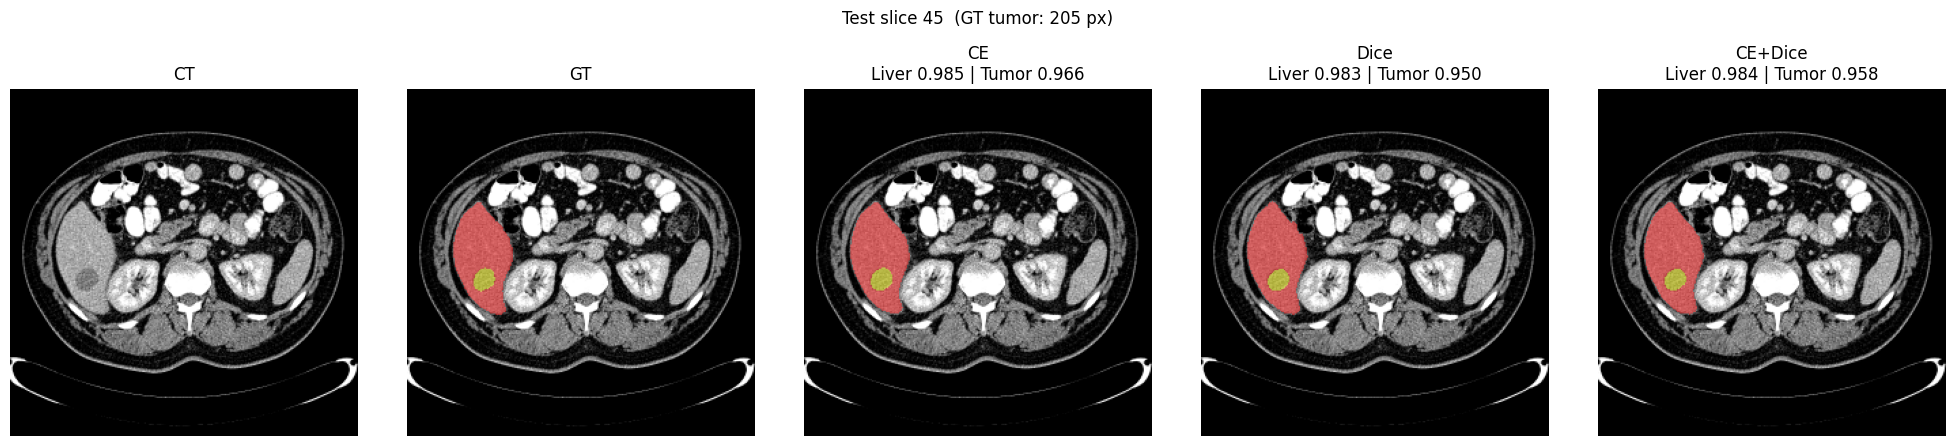

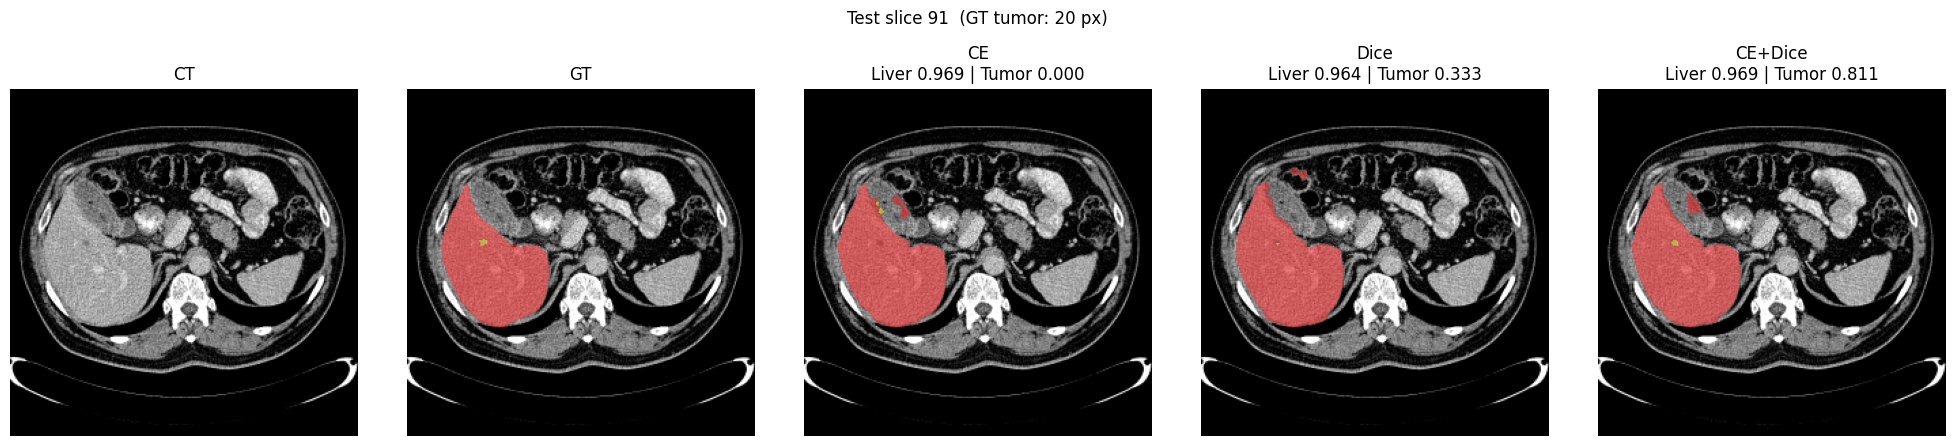

In [10]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["red", "yellow"])          # 1 = liver (red), 2 = tumor (yellow)

def slice_dice(pred, gt, c):
    """한 slice의 클래스 c Dice. 정답·예측이 둘 다 비면 nan"""
    p, t = (pred == c), (gt == c)
    denom = p.sum() + t.sum()
    return float("nan") if denom == 0 else (2 * (p & t).sum() / denom).item()

def show(idx):
    # ① 데이터 준비: 같은 slice 하나
    image, gt = test_ds[idx]
    preds = {name: predict(net, image) for name, net in models.items()}
    ct = image[0].numpy()                          # (1,H,W) → (H,W)

    # ② 5칸 구성: (제목, 겹칠 마스크)
    names = {"ce": "CE", "dice": "Dice", "ce_dice": "CE+Dice"}
    panels = [("CT", None), ("GT", gt)] + [(k, p) for k, p in preds.items()]

    # ③ 칸마다: CT → 마스크 겹치기 → 제목
    fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
    for ax, (key, m) in zip(axes, panels):
        ax.imshow(ct, cmap="gray", vmin=0, vmax=1)                 # 바탕 CT (모든 칸 공통)
        title = names.get(key, key)
        if m is not None:
            m_np = m.numpy()
            ax.imshow(np.ma.masked_where(m_np == 0, m_np),         # 배경(0)은 투명
                      cmap=cmap, vmin=1, vmax=2, alpha=0.45)
            if key in preds:                                       # 예측 칸에만 Dice 표시
                title += f"\nLiver {slice_dice(m, gt, 1):.3f} | Tumor {slice_dice(m, gt, 2):.3f}"
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(f"Test slice {idx}  (GT tumor: {(gt == 2).sum().item()} px)")
    plt.tight_layout(rect=[0, 0, 1, 0.92])     # 위쪽 8%를 전체 제목 자리로 비워 둠
    plt.show()

show(idx_large)    # largest tumor slice (205 px)
show(idx_small)    # small tumor slice (20 px)
